In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("Census2022sample_F19.csv")
print("Initial shape: ", df.shape)
print(df.head())
print(df.info())

Initial shape:  (71220, 32)
        QID  DERH_HSIZE  DERH_HHSEX  DERH_HHPOP  DERH_HHAGE  H01_QUARTERS  \
0  10000003           2           2           1        44.0           5.0   
1  10000005           4           2           1        41.0           5.0   
2  10000008           3           1           2        76.0           1.0   
3  10000018           2           2           1        37.0           1.0   
4  10000024           1           1           5        34.0           1.0   

   H02_MAINDWELLING  H03_TENURE  H04_RDP  H05_WATERPIPED  ...  H12_DVD_PLAYER  \
0              88.0         8.0      8.0             3.0  ...             2.0   
1              88.0         8.0      8.0             1.0  ...             2.0   
2               1.0         4.0      2.0             1.0  ...             2.0   
3               1.0         9.0      9.0             1.0  ...             9.0   
4               1.0         4.0      2.0             1.0  ...             2.0   

   H12_MOTOR_CAR  H12_

In [4]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

numeric_cols = df.select_dtypes(include=[np.number]).columns
categorical_cols = df.select_dtypes(exclude=[np.number]).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna("Unknown")

    

In [5]:
df = df.drop_duplicates()

In [6]:
if 'derh_hhage' in df.columns:
    df['derh_hhage'] = df['derh_hhage'].astype(int)
    df = df[(df['derh_hhage'] >= 0) & (df['derh_hhage'] <= 100)]  # realistic ages

if 'derh_hhsex' in df.columns:
    df['derh_hhsex'] = df['derh_hhsex'].replace({
        1: 'Male',
        2: 'Female'
    })

if 'derh_hhsize' in df.columns:
    df = df[df['derh_hhsize'] <= 20] 

In [7]:
print("Cleaned shape:", df.shape)
print(df.describe(include='all'))

Cleaned shape: (71217, 32)
                 qid    derh_hsize derh_hhsex    derh_hhpop    derh_hhage  \
count   7.121700e+04  71217.000000      71217  71217.000000  71217.000000   
unique           NaN           NaN          2           NaN           NaN   
top              NaN           NaN       Male           NaN           NaN   
freq             NaN           NaN      36913           NaN           NaN   
mean    1.030418e+07      2.988388        NaN      2.086988     46.892919   
std     1.755891e+05      1.777010        NaN      1.204969     14.417446   
min     1.000000e+07      1.000000        NaN      1.000000     12.000000   
25%     1.015163e+07      2.000000        NaN      1.000000     36.000000   
50%     1.030426e+07      3.000000        NaN      2.000000     46.000000   
75%     1.045652e+07      4.000000        NaN      3.000000     56.000000   
max     1.060773e+07     10.000000        NaN      5.000000    100.000000   

        h01_quarters  h02_maindwelling    h03_te

In [8]:
print(df['derh_hhsex'].value_counts())
print(df['h05_waterpiped'].value_counts())


Male      36913
Female    34304
Name: derh_hhsex, dtype: int64
1.0    58091
2.0     6013
3.0     4573
7.0     1186
4.0      895
5.0      263
6.0      196
Name: h05_waterpiped, dtype: int64


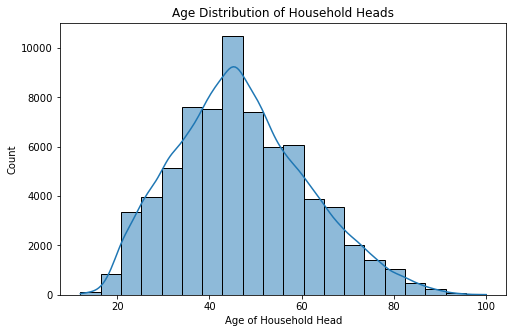

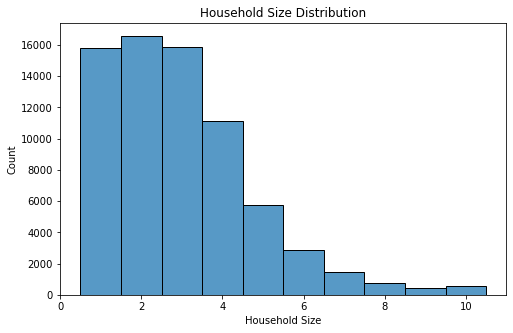

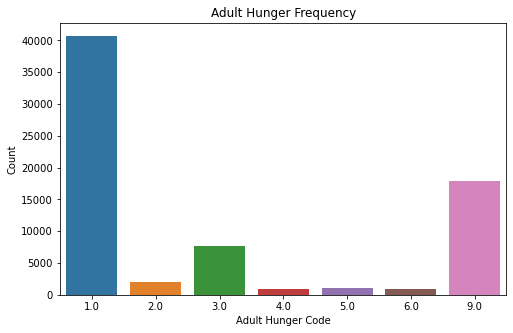

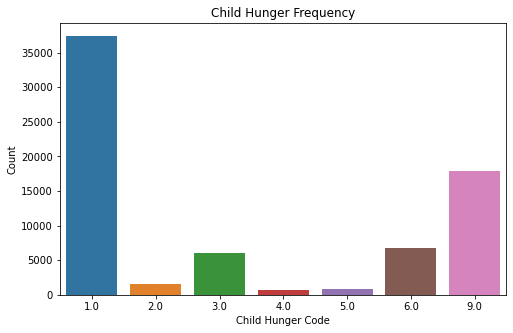

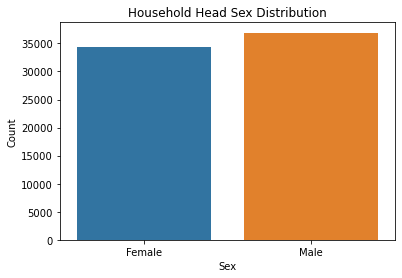

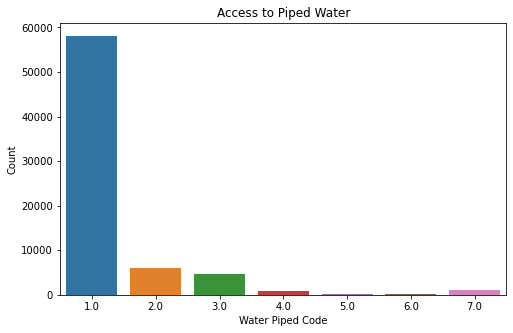

In [9]:
# --- Age distribution of household heads ---
plt.figure(figsize=(8,5))
sns.histplot(df['derh_hhage'], bins=20, kde=True)
plt.title("Age Distribution of Household Heads")
plt.xlabel("Age of Household Head")
plt.ylabel("Count")
plt.show()

# --- Household size distribution ---
plt.figure(figsize=(8,5))
sns.histplot(df['derh_hsize'], bins=10, discrete=True)
plt.title("Household Size Distribution")
plt.xlabel("Household Size")
plt.ylabel("Count")
plt.show()

# --- Adult hunger frequency ---
plt.figure(figsize=(8,5))
sns.countplot(x='a4_adult_hunger', data=df)
plt.title("Adult Hunger Frequency")
plt.xlabel("Adult Hunger Code")
plt.ylabel("Count")
plt.show()

# --- Child hunger frequency ---
plt.figure(figsize=(8,5))
sns.countplot(x='a5_child_hunger', data=df)
plt.title("Child Hunger Frequency")
plt.xlabel("Child Hunger Code")
plt.ylabel("Count")
plt.show()

# --- Household head sex distribution ---
plt.figure(figsize=(6,4))
sns.countplot(x='derh_hhsex', data=df)
plt.title("Household Head Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.show()

# --- Access to piped water ---
plt.figure(figsize=(8,5))
sns.countplot(x='h05_waterpiped', data=df)
plt.title("Access to Piped Water")
plt.xlabel("Water Piped Code")
plt.ylabel("Count")
plt.show()

Household Head Sex vs Access to Piped Water
h05_waterpiped    1.0   2.0   3.0  4.0  5.0  6.0  7.0
derh_hhsex                                           
Female          28381  2733  2058  399  121   85  527
Male            29710  3280  2515  496  142  111  659


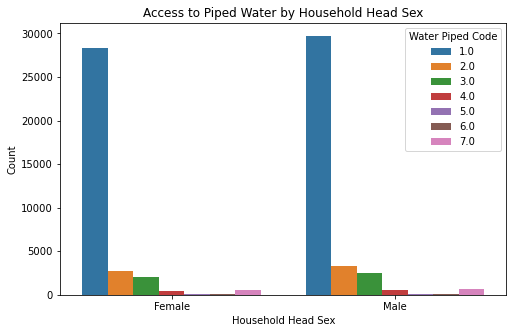

Household Size vs Adult Hunger
a4_adult_hunger   1.0  2.0   3.0  4.0  5.0  6.0   9.0
derh_hsize                                           
1                9348  482  2187  272  349  319  2864
2                9751  408  1351  184  189  246  4442
3                6898  351  1253  142  148  124  6949
4                6555  348  1008  142  125   86  2846
5                3909  207   784   95   83   61   619
6                2028  123   435   70   48   32   135
7                1054   68   247   37   24   15    38
8                 517   38   142   14   18   13    23
9                 289   23    75   13    4    3    14
10                345   39   116   19   14    5    14


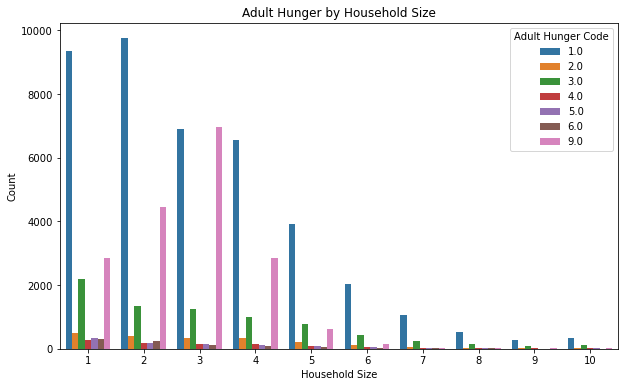

Household Head Sex vs Adult Hunger
a4_adult_hunger    1.0   2.0   3.0  4.0  5.0  6.0   9.0
derh_hhsex                                             
Female           18265  1024  3847  493  495  438  9742
Male             22429  1063  3751  495  507  466  8202


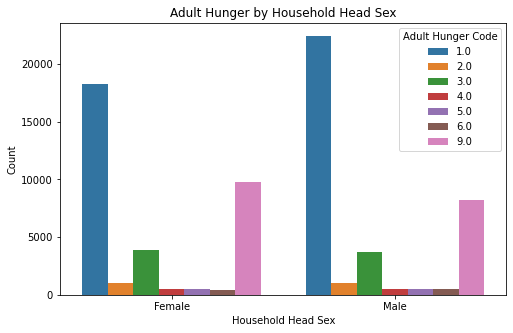

Dwelling Type vs Tenure
h03_tenure         1.0   2.0   3.0    4.0   5.0  6.0  7.0   8.0    9.0
h02_maindwelling                                                      
1.0               5747  1769  4759  14377  4043  666  310     0  17400
2.0                 89    17    28    111   140    8    2     0     18
3.0               1438   508   323    413   178   18   15     0    100
4.0                140    15   119    166    17    6    2     0     18
5.0                193    30   162    169    26    7    6     0     23
6.0                285   145   282    894   286   49   29     0     63
7.0                935   106   158    491   397   40   22     0     64
8.0               1159   143    40    395   849   72   20     0     97
9.0                418   104    55    889  2711  183   19     0    140
10.0                 3     1     0      0     5    1    0     0      0
11.0                40    13    14     36    28   29    8     0      0
88.0                 0     0     0      0     0    0 

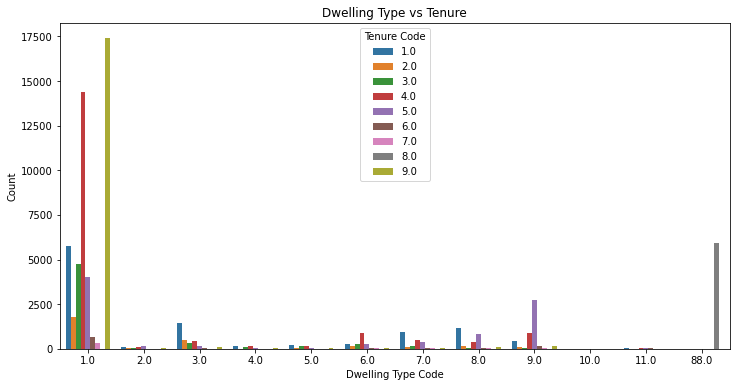

Mean household size by sex of household head:
derh_hhsex
Female    3.084917
Male      2.898681
Name: derh_hsize, dtype: float64

Average age of household head by tenure type:
h03_tenure
1.0    40.477362
2.0    47.114346
3.0    47.116330
4.0    54.331810
5.0    42.885253
6.0    45.704356
7.0    47.981524
8.0    41.441162
9.0    46.864587
Name: derh_hhage, dtype: float64


In [10]:
# --- Cross-tabulation: Household head sex vs access to piped water ---
ct_sex_water = pd.crosstab(df['derh_hhsex'], df['h05_waterpiped'])
print("Household Head Sex vs Access to Piped Water")
print(ct_sex_water)

plt.figure(figsize=(8,5))
sns.countplot(x='derh_hhsex', hue='h05_waterpiped', data=df)
plt.title("Access to Piped Water by Household Head Sex")
plt.xlabel("Household Head Sex")
plt.ylabel("Count")
plt.legend(title="Water Piped Code")
plt.show()

# --- Cross-tabulation: Household size vs adult hunger ---
ct_size_hunger = pd.crosstab(df['derh_hsize'], df['a4_adult_hunger'])
print("Household Size vs Adult Hunger")
print(ct_size_hunger)

plt.figure(figsize=(10,6))
sns.countplot(x='derh_hsize', hue='a4_adult_hunger', data=df)
plt.title("Adult Hunger by Household Size")
plt.xlabel("Household Size")
plt.ylabel("Count")
plt.legend(title="Adult Hunger Code")
plt.show()

# --- Cross-tabulation: Household head sex vs adult hunger ---
ct_sex_hunger = pd.crosstab(df['derh_hhsex'], df['a4_adult_hunger'])
print("Household Head Sex vs Adult Hunger")
print(ct_sex_hunger)

plt.figure(figsize=(8,5))
sns.countplot(x='derh_hhsex', hue='a4_adult_hunger', data=df)
plt.title("Adult Hunger by Household Head Sex")
plt.xlabel("Household Head Sex")
plt.ylabel("Count")
plt.legend(title="Adult Hunger Code")
plt.show()

# --- Dwelling type vs tenure ---
ct_dwelling_tenure = pd.crosstab(df['h02_maindwelling'], df['h03_tenure'])
print("Dwelling Type vs Tenure")
print(ct_dwelling_tenure)

plt.figure(figsize=(12,6))
sns.countplot(x='h02_maindwelling', hue='h03_tenure', data=df)
plt.title("Dwelling Type vs Tenure")
plt.xlabel("Dwelling Type Code")
plt.ylabel("Count")
plt.legend(title="Tenure Code")
plt.show()

# --- Summary statistics examples ---
print("Mean household size by sex of household head:")
print(df.groupby('derh_hhsex')['derh_hsize'].mean())

print("\nAverage age of household head by tenure type:")
print(df.groupby('h03_tenure')['derh_hhage'].mean())


Ownership distribution for h12_refrigerator:
1.0    45669
9.0    17916
2.0     7632
Name: h12_refrigerator, dtype: int64


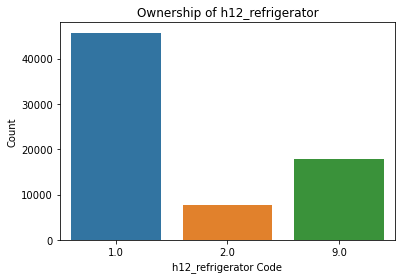


Ownership distribution for h12_computer:
2.0    33099
1.0    20197
9.0    17921
Name: h12_computer, dtype: int64


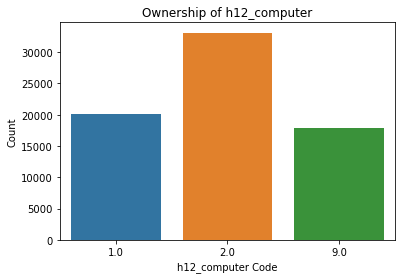


Ownership distribution for h12_motor_car:
2.0    29413
1.0    23882
9.0    17922
Name: h12_motor_car, dtype: int64


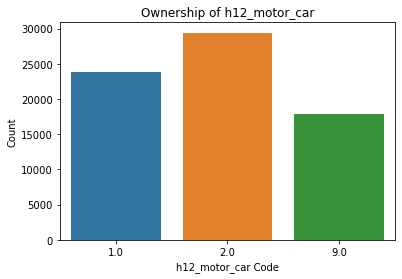


Ownership distribution for h12_cellphone:
1.0    48855
9.0    17922
2.0     4440
Name: h12_cellphone, dtype: int64


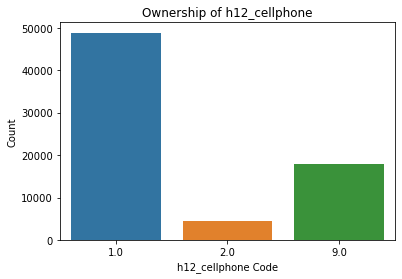

In [11]:
# --- Asset ownership analysis ---
asset_cols = ['h12_refrigerator','h12_computer','h12_motor_car','h12_cellphone']

for col in asset_cols:
    print(f"\nOwnership distribution for {col}:")
    print(df[col].value_counts())

    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df)
    plt.title(f"Ownership of {col}")
    plt.xlabel(f"{col} Code")
    plt.ylabel("Count")
    plt.show()


Ownership distribution for h12_refrigerator:
1.0    45669
9.0    17916
2.0     7632
Name: h12_refrigerator, dtype: int64


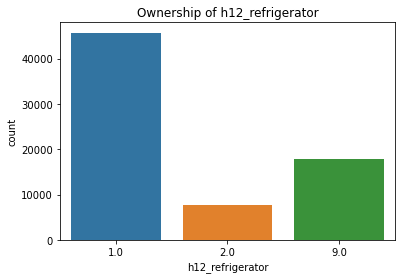


Ownership distribution for h12_computer:
2.0    33099
1.0    20197
9.0    17921
Name: h12_computer, dtype: int64


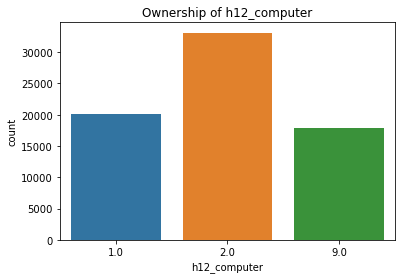


Ownership distribution for h12_motor_car:
2.0    29413
1.0    23882
9.0    17922
Name: h12_motor_car, dtype: int64


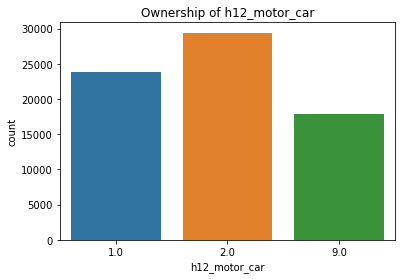


Ownership distribution for h12_cellphone:
1.0    48855
9.0    17922
2.0     4440
Name: h12_cellphone, dtype: int64


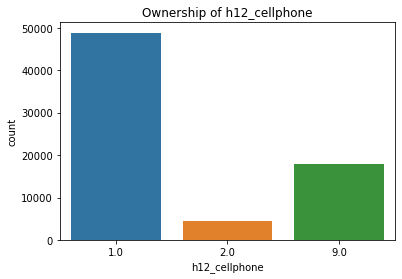

In [12]:
asset_cols = ['h12_refrigerator','h12_computer','h12_motor_car','h12_cellphone']
for col in asset_cols:
    print(f"\nOwnership distribution for {col}:")
    print(df[col].value_counts())
    sns.countplot(x=col, data=df)
    plt.title(f"Ownership of {col}")
    plt.show()


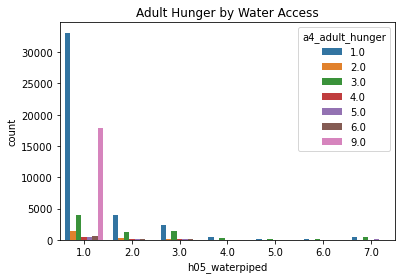

In [13]:
pd.crosstab(df['h05_waterpiped'], df['a4_adult_hunger'])
sns.countplot(x='h05_waterpiped', hue='a4_adult_hunger', data=df)
plt.title("Adult Hunger by Water Access")
plt.show()


In [14]:
if 'educationlevel' in df.columns:
    pd.crosstab(df['educationlevel'], df['h03_tenure'])
